<a href="https://colab.research.google.com/github/arpancoding/Explainable-emotion-detection/blob/main/emotion_explainability_project_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explainable Fine-Grained Emotion Detection
Predicts a fine-grained emotion label for a short text passage **and** highlights the word(s)/phrase(s) responsible for that prediction, using Integrated Gradients over a fine-tuned BERT classifier.

Run cells top to bottom. Use a GPU runtime: `Runtime -> Change runtime type -> T4 GPU`.

## 1. Install dependencies

In [ ]:
!pip install -q transformers datasets evaluate accelerate scikit-learn matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.6 MB/s eta 0:00:00


## 2. Imports

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)
from sklearn.metrics import f1_score, precision_score, recall_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


## 3. Load GoEmotions

In [ ]:
raw_ds = load_dataset("google-research-datasets/go_emotions", "simplified")
label_names = raw_ds["train"].features["labels"].feature.names
num_labels = len(label_names)
print(f"{num_labels} labels:", label_names)
print(raw_ds)


README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

...

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

28 labels: ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']
DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})


## 4. Preprocessing
GoEmotions is multi-label (a sentence can have several emotions at once, or 'example_very_unclear' cases).
We build a multi-hot vector per example and tokenize the text.

In [ ]:
MODEL_NAME = "distilbert-base-uncased"   # swap for "bert-base-uncased" for a stronger but slower model
MAX_LEN = 64

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def preprocess(batch):
    enc = tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)
    multi_hot = np.zeros((len(batch["text"]), num_labels), dtype=np.float32)
    for i, labs in enumerate(batch["labels"]):
        for l in labs:
            multi_hot[i, l] = 1.0
    enc["labels"] = multi_hot.tolist()
    return enc

encoded_ds = raw_ds.map(preprocess, batched=True, remove_columns=raw_ds["train"].column_names)
encoded_ds.set_format("torch")
class MultiLabelCollator:
    """Pads inputs normally, but force-casts the multi-hot labels to float32
    so BCEWithLogitsLoss (used for multi_label_classification) doesn't choke
    on an int64 tensor."""
    def __init__(self, tokenizer):
        self.base_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    def __call__(self, features):
        labels = [f.pop("labels") for f in features]
        batch = self.base_collator(features)
        batch["labels"] = torch.stack([torch.as_tensor(l, dtype=torch.float32) for l in labels])
        return batch

collator = MultiLabelCollator(tokenizer)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/43410 [00:00<?, ? examples/s]

Map:   0%|          | 0/5426 [00:00<?, ? examples/s]

Map:   0%|          | 0/5427 [00:00<?, ? examples/s]

## 5. Model

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    problem_type="multi_label_classification"
).to(device)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 6. Metrics + Trainer
Micro-F1 rewards frequent labels; macro-F1 is fairer on GoEmotions' long tail of rare emotions -- report both.

In [ ]:
THRESHOLD = 0.3

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= THRESHOLD).astype(int)
    return {
        "f1_micro": f1_score(labels, preds, average="micro", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "precision_micro": precision_score(labels, preds, average="micro", zero_division=0),
        "recall_micro": recall_score(labels, preds, average="micro", zero_division=0),
    }

args = TrainingArguments(
    output_dir="./emotion_model",
    eval_strategy="epoch",
    save_strategy="epoch",
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    learning_rate=2e-5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    logging_steps=200,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=encoded_ds["train"],
    eval_dataset=encoded_ds["validation"],
    processing_class=tokenizer,
    data_collator=collator,
    compute_metrics=compute_metrics,
)


## 7. Train
On a T4 GPU, the full train split (~44k examples) takes roughly 15-25 min for 3 epochs.
To iterate faster while debugging, first try on a subset: `encoded_ds['train'].select(range(5000))`.

In [ ]:
# If you're on CPU (no GPU available), full-scale training is impractical.
# Set USE_SUBSET = True to train on a small slice for debugging/demo purposes.
USE_SUBSET = not torch.cuda.is_available()
if USE_SUBSET:
    print("No GPU detected -- training on a small subset for speed. "
          "Switch to a Colab GPU runtime for full-scale training.")
    trainer.train_dataset = encoded_ds["train"].select(range(2000))
    trainer.args.num_train_epochs = 1

trainer.train()


Epoch,Training Loss,Validation Loss,F1 Micro,F1 Macro,Precision Micro,Recall Micro
1,0.102786,0.094232,0.569577,0.335958,0.605975,0.537304
2,0.087063,0.086702,0.592992,0.422321,0.599936,0.586207
3,0.078509,0.085920,0.598658,0.430870,0.603182,0.594201


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=4071, training_loss=0.10408560575533488, metrics={'train_runtime': 503.0423, 'train_samples_per_second': 258.885, 'train_steps_per_second': 8.093, 'total_flos': 1220688277806096.0, 'train_loss': 0.10408560575533488, 'epoch': 3.0})

## 8. Evaluate on the held-out test split

In [ ]:
test_metrics = trainer.evaluate(encoded_ds["test"])
print(test_metrics)


Training Loss,Validation Loss,Epoch,F1 Micro,F1 Macro,Precision Micro,Recall Micro
0.078509,0.084862,3,0.601297,0.432265,0.601868,0.600727


{'eval_loss': 0.08486203849315643, 'eval_f1_micro': 0.601296852759766, 'eval_f1_macro': 0.43226473293625706, 'eval_precision_micro': 0.6018679753047332, 'eval_recall_micro': 0.6007268130826355}


## 9. Save the fine-tuned model

In [ ]:
SAVE_DIR = "./emotion_model_final"
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print("Saved to", SAVE_DIR)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to ./emotion_model_final


## 10. Explainability: Integrated Gradients over input embeddings
For a predicted emotion, we attribute the logit back to each input token by integrating gradients
along a straight path from a zero (baseline) embedding to the actual embedding. Tokens with the
largest attribution magnitude are the ones "most responsible" for the prediction.

In [ ]:
model.eval()
embedding_layer = model.get_input_embeddings()

def integrated_gradients(text, target_label_idx, steps=50):
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
    input_ids = enc["input_ids"]
    attention_mask = enc["attention_mask"]

    input_embeds = embedding_layer(input_ids).detach()
    baseline_embeds = torch.zeros_like(input_embeds)

    total_grads = torch.zeros_like(input_embeds)
    for step in range(1, steps + 1):
        alpha = step / steps
        interp_embeds = baseline_embeds + alpha * (input_embeds - baseline_embeds)
        interp_embeds.requires_grad_(True)

        outputs = model(inputs_embeds=interp_embeds, attention_mask=attention_mask)
        logit = outputs.logits[0, target_label_idx]

        grads = torch.autograd.grad(logit, interp_embeds, retain_graph=False)[0]
        total_grads += grads

    avg_grads = total_grads / steps
    attributions = (input_embeds - baseline_embeds) * avg_grads   # (1, seq_len, hidden)
    token_scores = attributions.sum(dim=-1).squeeze(0).detach().cpu().numpy()  # (seq_len,)

    tokens = tokenizer.convert_ids_to_tokens(input_ids[0])
    return tokens, token_scores

def predict_and_explain(text, top_k_labels=1, top_k_tokens=5):
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
    with torch.no_grad():
        logits = model(**enc).logits
    probs = torch.sigmoid(logits)[0].cpu().numpy()

    top_label_idxs = probs.argsort()[::-1][:top_k_labels]

    results = []
    for idx in top_label_idxs:
        tokens, scores = integrated_gradients(text, int(idx))
        # drop special tokens ([CLS]/[SEP]/[PAD]) from the ranking
        keep = [i for i, t in enumerate(tokens) if t not in tokenizer.all_special_tokens]
        pairs = sorted(((tokens[i], scores[i]) for i in keep), key=lambda p: -abs(p[1]))[:top_k_tokens]
        results.append({
            "emotion": label_names[idx],
            "probability": float(probs[idx]),
            "top_tokens": pairs,
            "all_tokens": tokens,
            "all_scores": scores,
        })
    return results


## 11. Visualize the highlighted span

In [ ]:
def visualize_attribution(tokens, scores, title=""):
    scores = np.array(scores)
    norm = scores / (np.abs(scores).max() + 1e-8)
    fig, ax = plt.subplots(figsize=(max(6, len(tokens) * 0.6), 1.5))
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    x = 0
    for tok, s in zip(tokens, norm):
        color = plt.cm.Reds(abs(s)) if s > 0 else plt.cm.Blues(abs(s))
        ax.text(x, 0.5, tok.replace("##", ""), fontsize=12,
                bbox=dict(facecolor=color, edgecolor="none", alpha=0.8, pad=3))
        x += len(tok) * 0.03 + 0.05
    plt.show()


## 12. Try it out

Text: I can't believe you forgot my birthday again, this is so disappointing.
Predicted emotion: disappointment  (p=0.37)
Top contributing tokens: [('disappointing', np.float32(2.5197518)), ('so', np.float32(0.889385)), ('is', np.float32(0.46786326)), ('this', np.float32(0.20882145)), ('you', np.float32(0.15988433))]


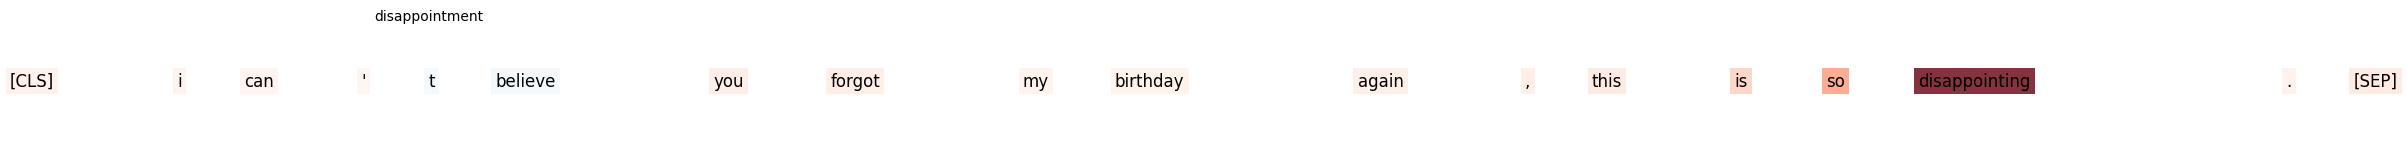

--------------------------------------------------------------------------------
Text: Thank you so much for helping me move, I really appreciate it!
Predicted emotion: gratitude  (p=0.96)
Top contributing tokens: [('thank', np.float32(3.2626219)), ('appreciate', np.float32(1.072709)), ('you', np.float32(0.81245327)), ('much', np.float32(0.71809494)), ('!', np.float32(0.66991645))]


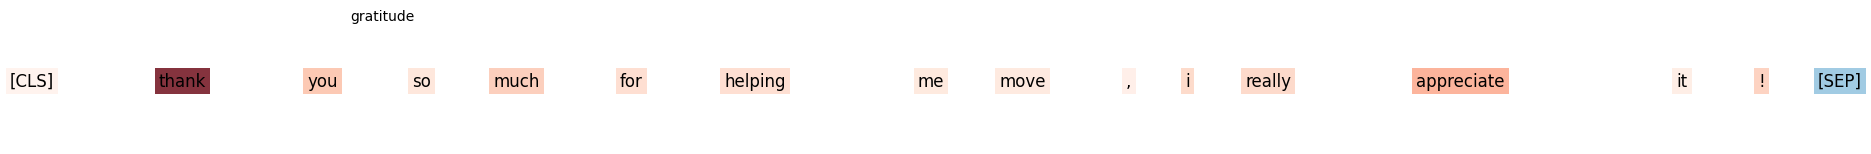

--------------------------------------------------------------------------------
Text: I'm terrified about the exam results coming out tomorrow.
Predicted emotion: fear  (p=0.75)
Top contributing tokens: [('terrified', np.float32(4.4604063)), ('m', np.float32(0.8347331)), ('i', np.float32(0.73317873)), ("'", np.float32(0.7162038)), ('the', np.float32(0.70571804))]


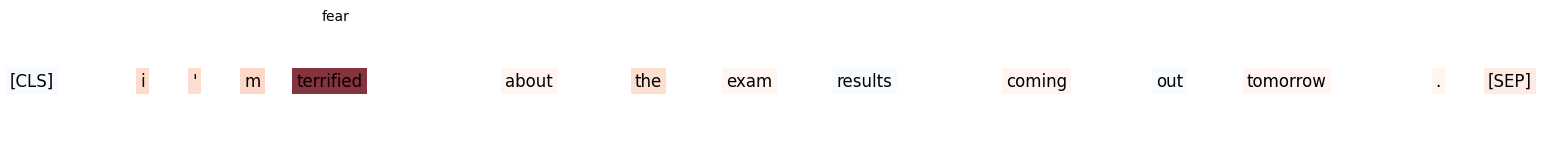

--------------------------------------------------------------------------------


In [ ]:
examples = [
    "I can't believe you forgot my birthday again, this is so disappointing.",
    "Thank you so much for helping me move, I really appreciate it!",
    "I'm terrified about the exam results coming out tomorrow.",
]

for text in examples:
    result = predict_and_explain(text, top_k_labels=1, top_k_tokens=5)[0]
    print(f"Text: {text}")
    print(f"Predicted emotion: {result['emotion']}  (p={result['probability']:.2f})")
    print("Top contributing tokens:", result["top_tokens"])
    visualize_attribution(result["all_tokens"], result["all_scores"], title=result["emotion"])
    print("-" * 80)
